# Live Guided Virtual Lab 4: Tree of Thoughts — Solution

> Yao, Yu, Zhao, Shafran, Griffiths, Cao & Narasimhan, **"Tree of Thoughts: Deliberate Problem Solving with Large Language Models"**, NeurIPS 2023 — [arXiv:2305.10601](https://arxiv.org/abs/2305.10601) · [official code](https://github.com/princeton-nlp/tree-of-thought-llm)

In this lab you will rebuild the paper's core contribution — a **search over "thoughts"** instead of a single left-to-right chain — and benchmark it on the paper's own task and data:

1. **Why trees?** The paper's framing: IO → CoT → CoT-SC → ToT (Figure 1).
2. **The four ToT design questions** (§3): decomposition, generation, evaluation, search.
3. **The benchmark data**: the Game of 24 puzzle set the authors *scraped from 4nums.com* — we load the very same file and test on the paper's hard slice (games 901–1,000).
4. **Build the machinery**: thought generator `G(·)`, state evaluator `V(·)`, and ToT-BFS (Algorithm 1), using the paper's *actual prompts*.
5. **Benchmark**: IO vs. CoT vs. ToT on the paper's test puzzles — a small-scale local replication of the paper's Table 2.

Everything runs on a local Hugging Face model, so no API key is needed.

## 1. From IO to CoT to ToT — why search? (§1–§2)

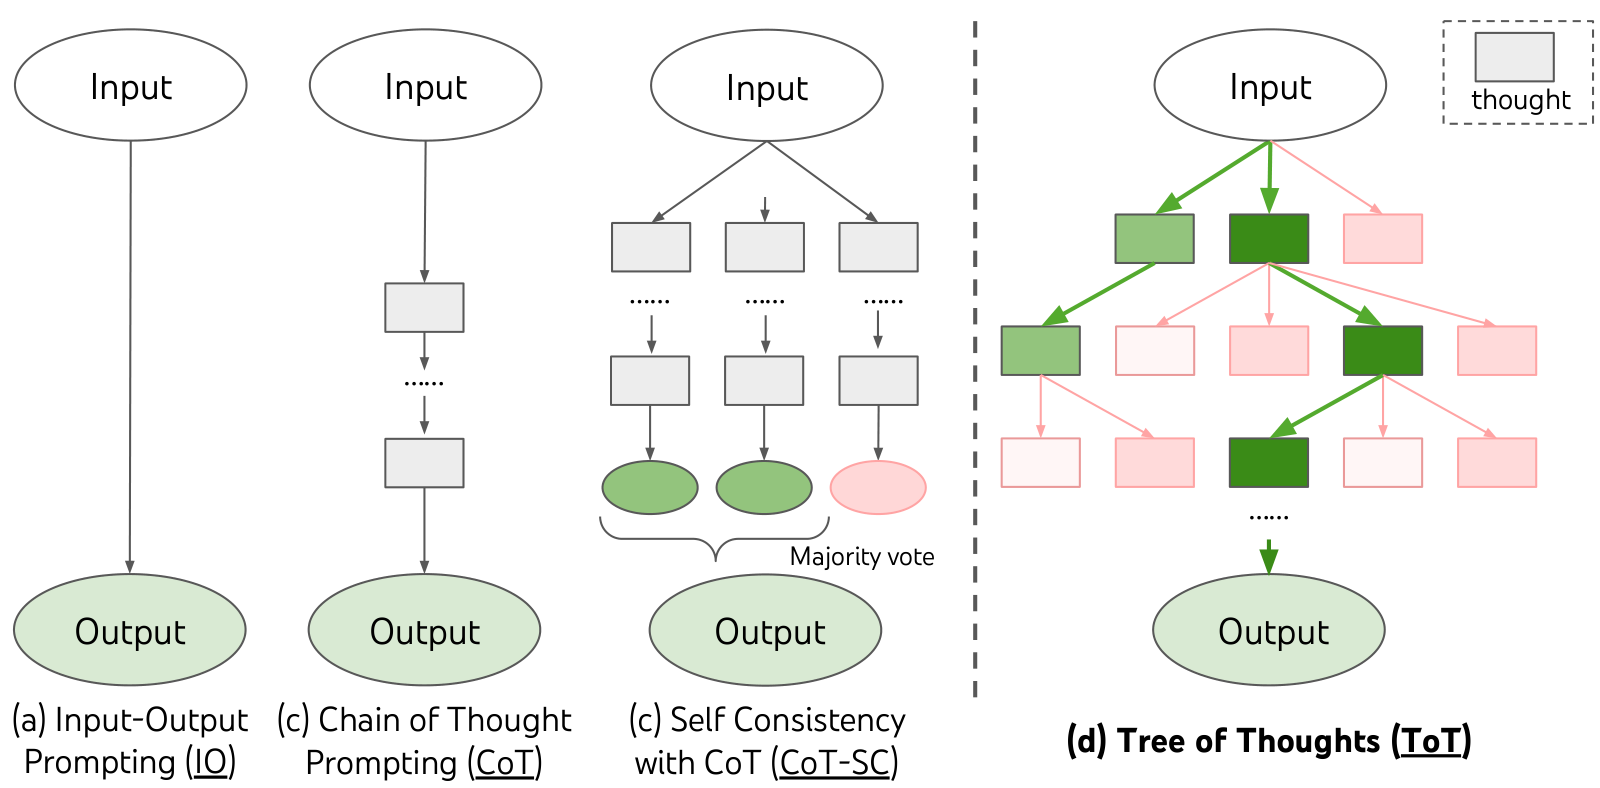

*Paper Figure 1 — "Schematic illustrating various approaches to problem solving with LLMs. Each rectangle box represents a thought, which is a coherent language sequence that serves as an intermediate step toward problem solving."*

The paper formalizes the progression shown above (§2):

- **Input-Output (IO) prompting**: the LM maps input `x` directly to output `y` — one shot, no intermediate reasoning.
- **Chain of Thought (CoT)**: the LM samples a *chain* of intermediate thoughts `z₁ … zₙ` left-to-right before answering. Powerful, but the chain is sampled once and **never revised**.
- **Self-Consistency with CoT (CoT-SC)**: sample `k` independent chains, take the majority-vote answer. More robust, but there is still **no local exploration inside a chain**, and majority voting only works when the output space is small (e.g. one number).
- **Tree of Thoughts (ToT)**: maintain a *tree* where each node is a **state** `s = [x, z₁…ᵢ]` — the input plus the thoughts so far. The LM *generates* multiple candidate next thoughts per state, *evaluates* states heuristically, and a search algorithm (BFS/DFS) decides which branches to expand, with lookahead and backtracking.

**Why does left-to-right decoding fail?** Drawing on Newell & Simon's classic view of human problem solving as *search through a problem space*, the paper identifies two shortcomings of CoT-style generation: (1) *locally*, it never explores different continuations from the same point, and (2) *globally*, it has no planning, lookahead, or backtracking. This is not hypothetical — the paper's error analysis (Figure 5b) found that **about 60% of CoT samples fail the Game of 24 at the very first step**: once the model commits to a bad opening like `4 + 9`, everything after it is wasted tokens.

ToT's conceptual benefits (§3): **generality** (IO/CoT/CoT-SC are special cases — trees of depth/breadth 1), **modularity** (swap the LM, decomposition, generator, evaluator, or search independently), **adaptability**, and **convenience** (no training — just a pre-trained LM).

## 2. The Four ToT Design Questions (§3)

A specific instantiation of ToT answers four questions. For Game of 24 the paper chose:

| # | Question | Game of 24 answer |
|---|---|---|
| 1 | **Thought decomposition** — what is one "thought"? | One arithmetic equation combining two remaining numbers (3 steps total: 4 → 3 → 2 → 1 numbers) |
| 2 | **Thought generator G(p_θ, s, k)** — *sample* or *propose*? | **Propose**: enumerate candidate equations from the current remaining numbers |
| 3 | **State evaluator V(p_θ, S)** — *value* or *vote*? | **Value**: classify each state as `sure / likely / impossible`, sampled 3× |
| 4 | **Search algorithm** — BFS or DFS? | **BFS** with breadth b = 5, depth T = 3 |

**Thought granularity (§3 point 1).** A thought should be *"small enough so that LMs can generate promising and diverse samples, yet big enough so that LMs can evaluate its prospect toward problem solving."* Across the paper's three tasks a thought is a couple of words (Crosswords), one equation line (Game of 24), or a whole paragraph plan (Creative Writing).

**Sample vs. Propose (§3 point 2).**
- *Sample*: draw k i.i.d. thoughts from a CoT prompt — best when the thought space is rich (paragraph-sized thoughts), where i.i.d. sampling gives diversity.
- *Propose*: ask the LM to enumerate k candidate next steps **in one prompt** — better when the thought space is constrained (one word or one line), because proposing in shared context avoids duplicates.

**Value vs. Vote (§3 point 3).**
- *Value*: score each state independently — via a few *lookahead* simulations (e.g. "5, 5, 14 can reach 24 via 5 + 5 + 14") plus *commonsense* (e.g. "1 2 3 are too small"). The paper stresses these valuations *"do not need to be perfect, and only need to be approximately helpful for decision making."*
- *Vote*: present multiple states together and let the LM elect the most promising — used when direct scoring is hard (e.g. coherency of writing plans); a "step-wise self-consistency."

Either way, the LM can be prompted **multiple times and aggregated** to trade compute for a more robust heuristic — the paper samples the value prompt 3× per state.

## 3. The Benchmark: Game of 24, Scraped from 4nums.com (§4.1)

**The task.** Use 4 numbers and basic arithmetic (`+ - * /`) to obtain 24, using each input number **exactly once**. Given `4 9 10 13`, one solution is `(10 - 4) * (13 - 9) = 24`.

**Where the paper's data actually comes from.** This is the part people usually skim — the benchmark is *scraped from a puzzle website*. Quoting the task setup verbatim:

> *"We scrape data from [4nums.com](https://www.4nums.com/game/difficulties/), which has 1,362 games that are sorted from easy to hard by human solving time, and use a subset of relatively hard games indexed 901–1,000 for testing. For each task, we consider the output as success if it is a valid equation that equals 24 and uses the input numbers each exactly once. We report the success rate across 100 games as the metric."*

So the dataset carries **human difficulty labels for free**: 4nums.com ranks every game by how long humans took to solve it (and what fraction solved it at all). Sorting by that ranking is what lets the paper test on a *hard* slice — easy games wouldn't separate ToT from CoT, because CoT already solves them.

**We use the same file.** The official ToT repository ships the scrape as `24.csv` with columns:

| Column | Meaning |
|---|---|
| `Rank` | 1–1,362, easy → hard by human solve time |
| `Puzzles` | the four numbers, e.g. `4 5 6 10` |
| `AMT (s)` | mean human solve time in seconds |
| `Solved rate` | fraction of humans who solved it |
| `1-sigma Mean (s)` / `1-sigma STD (s)` | solve-time statistics |

Below we download it (with a small embedded fallback in case you're offline) and slice out the paper's test set, rows 901–1,000.

## Setup

In [ ]:
!pip install -q transformers torch pandas numpy matplotlib tqdm accelerate

In [ ]:
import io, re, time, warnings
from fractions import Fraction
from typing import List, Dict, Tuple, Optional
from dataclasses import dataclass, field
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer, pipeline
from transformers.utils import logging as hf_logging

# ── Model selection ───────────────────────────────────────────────
# Generation quality is the ToT bottleneck (paper Appendix B, Table 6:
# GPT-4 -> 74%, GPT-3.5 -> 19% on Game of 24). Pick by your hardware:
#   "Qwen/Qwen2.5-0.5B-Instruct"  fast smoke test - too weak: ToT finds ~0 valid moves
#   "Qwen/Qwen2.5-3B-Instruct"    recommended balance (CPU ok but slow; great on GPU)
#   "Qwen/Qwen2.5-7B-Instruct"    best local fidelity - GPU strongly recommended
MODEL_NAME = "Qwen/Qwen2.5-3B-Instruct"

# Quiet noisy HF generation warnings for a cleaner notebook
warnings.filterwarnings("ignore")
hf_logging.set_verbosity_error()

np.random.seed(42)
torch.manual_seed(42)
print(f"✓ Libraries imported  |  model = {MODEL_NAME}")

### Load the Paper's Test Data (the 4nums.com scrape)

The cell below fetches `24.csv` straight from the official repository — this file *is* the 4nums.com scrape the paper describes. If the download fails (offline, firewall), it falls back to an embedded copy of the first ten test games (ranks 901–910) so the rest of the lab still runs.

In [ ]:
DATA_URL = ("https://raw.githubusercontent.com/princeton-nlp/"
            "tree-of-thought-llm/master/src/tot/data/24/24.csv")

# Ranks 901-910 of the scrape, verbatim — the start of the paper's test slice.
FALLBACK_CSV = """Rank,Puzzles,AMT (s),Solved rate,1-sigma Mean (s),1-sigma STD (s)
901,4 5 6 10,10.02,90.30%,10.49,4.36
902,1 2 4 7,10.03,89.10%,10.3,4.82
903,2 5 8 11,10.03,85.90%,10.22,5.08
904,3 4 4 13,10.03,88.80%,10.08,4.15
905,6 7 8 9,10.03,84.50%,9.67,4.35
906,1 11 11 13,10.06,87.70%,10.01,4.25
907,1 8 10 11,10.07,86.90%,10.02,3.39
908,2 3 6 9,10.1,93.10%,10.54,4.14
909,1 3 5 9,10.11,90.60%,10.39,4.46
910,3 3 7 12,10.11,84.50%,10.02,5.26
"""

try:
    game24_df = pd.read_csv(DATA_URL)
    source = "official repo (full 4nums.com scrape)"
except Exception as e:
    print(f"Download failed ({e}); using embedded fallback rows 901-910")
    game24_df = pd.read_csv(io.StringIO(FALLBACK_CSV))
    source = "embedded fallback"

# The paper's test set: games indexed 901-1,000 (the "relatively hard" slice)
if len(game24_df) > 1000:
    paper_test_df = game24_df.iloc[900:1000].reset_index(drop=True)
else:
    paper_test_df = game24_df.reset_index(drop=True)

print(f"Loaded {len(game24_df)} games from {source}")
print(f"Test slice: {len(paper_test_df)} games "
      f"(ranks {paper_test_df['Rank'].min()}-{paper_test_df['Rank'].max()})")
if len(game24_df) > 1000:
    easy = game24_df.iloc[:100]["AMT (s)"].mean()
    hard = paper_test_df["AMT (s)"].mean()
    print(f"Mean human solve time — easiest 100 games: {easy:.1f}s | "
          f"paper's test games: {hard:.1f}s")
paper_test_df.head(10)

## Step 1: LLM Setup

A thin wrapper around a local Hugging Face chat model. Note that the paper's numbers were produced with GPT-4 (sampling temperature 0.7, same as here); with a small local model, expect the same *qualitative* behavior — search explores, prunes, sometimes solves — at a much lower success rate.

In [ ]:
class LLMClient:
    """Thin wrapper around a local Hugging Face text-generation pipeline."""

    def __init__(self, model_name: str = MODEL_NAME, temperature: float = 0.7):
        self.model_name = model_name
        self.temperature = temperature
        print(f"Loading {model_name}… (first run downloads weights)")
        self.tokenizer = AutoTokenizer.from_pretrained(model_name, trust_remote_code=True)
        self.model = AutoModelForCausalLM.from_pretrained(
            model_name,
            torch_dtype=torch.float16 if torch.cuda.is_available() else torch.float32,
            device_map="auto" if torch.cuda.is_available() else None,
            trust_remote_code=True,
        )
        # Prevent the default max_length=20 from colliding with max_new_tokens
        self.model.generation_config.max_length = None
        self.pipe = pipeline(
            "text-generation", model=self.model, tokenizer=self.tokenizer,
            device_map="auto" if torch.cuda.is_available() else None,
        )
        print(f"✓ Ready  |  device: {'GPU' if torch.cuda.is_available() else 'CPU'}")

    def generate(self, prompt: str, max_tokens: int = 400) -> str:
        try:
            out = self.pipe(
                [{"role": "user", "content": prompt}],
                max_new_tokens=max_tokens,
                temperature=self.temperature,
                do_sample=self.temperature > 0,
                top_p=0.9,
                pad_token_id=self.tokenizer.eos_token_id,
            )
            generated = out[0]["generated_text"]
            if isinstance(generated, list) and len(generated) > 1:
                return generated[-1]["content"].strip()
            return generated.strip()
        except Exception as e:
            print(f"Generation error: {e}")
            return ""

llm = LLMClient(MODEL_NAME)
print("✓ LLM ready")

## Step 2: Data Structures

The paper defines a **state** as `s = [x, z₁…ᵢ]` — the input plus the sequence of thoughts so far. Our node stores the compact equivalent for Game of 24:

- **`ToTNode`** — one node in the tree. `state` = remaining numbers (e.g. `"4 6 8"`); `thought` = the equation that produced it (e.g. `"8 * 8 = 64 (left: 4, 6, 64)"`). Following the parent chain recovers `z₁…ᵢ`.
- **`SearchResult`** — output of a full BFS run.

In [ ]:
@dataclass
class ToTNode:
    state: str                              # remaining numbers, e.g. "10 14"
    thought: str = "[START]"               # equation that produced this state
    score: float = 0.0                     # aggregated value from V(·)
    depth: int = 0
    parent: Optional["ToTNode"] = None
    children: List["ToTNode"] = field(default_factory=list)

    def path(self) -> List[str]:
        steps, node = [], self
        while node and node.thought != "[START]":
            steps.insert(0, node.thought)
            node = node.parent
        return steps

    def __repr__(self):
        return f"ToTNode(depth={self.depth}, score={self.score:.2f}, state={self.state!r})"


@dataclass
class SearchResult:
    solution: Optional[str]
    nodes_explored: int
    elapsed: float
    root: Optional[ToTNode] = None

print("✓ Data structures defined")

## Step 3: Arithmetic Utilities

Because Game of 24 is *mathematical*, parts of the pipeline the paper had to delegate to the LLM can be done **exactly** in Python:

1. **`solve24(nums)`** — pure-Python solver: answers definitively whether a set of numbers *can* reach 24. The paper's LLM value prompt approximates this with lookahead + commonsense; we can compute it exactly.
2. **`parse_equation(thought, prev_nums)`** — deterministically parses a proposed equation, verifies the arithmetic, and returns the correct remaining numbers. This replaces trusting the LLM-generated `(left: ...)` annotation.
3. **`check_answer(puzzle, expression)`** — the paper's **success criterion**, verbatim: *"a valid equation that equals 24 and uses the input numbers each exactly once."* The paper checks final answers with an LLM judge (`value_last_step_prompt` in the official repo); ours is the deterministic version, and we'll use it to score the IO/CoT baselines later.

In [ ]:
def solve24(nums: List[float]) -> bool:
    """
    Return True if `nums` can reach 24 using + - * / (each number used once).
    Uses exact arithmetic via fractions to avoid floating-point errors.
    """
    fracs = [Fraction(n).limit_denominator(1000) for n in nums]
    if len(fracs) == 1:
        return fracs[0] == 24
    for i in range(len(fracs)):
        for j in range(len(fracs)):
            if i == j:
                continue
            rest = [fracs[k] for k in range(len(fracs)) if k != i and k != j]
            a, b = fracs[i], fracs[j]
            candidates = [a + b, a - b, a * b]
            if b != 0:
                candidates.append(a / b)
            if any(solve24(rest + [c]) for c in candidates):
                return True
    return False


def parse_equation(thought: str, prev_nums: List[float]) -> Tuple[bool, List[float]]:
    """
    Parse an equation string like '9 + 4 = 13 (left: 10, 13, 13)',
    verify the arithmetic is correct, and return (valid, new_remaining_nums).

    Returns (False, prev_nums) if the equation is malformed or arithmetically wrong.
    """
    m = re.search(r"([\d.]+)\s*([\+\-\*/])\s*([\d.]+)\s*=\s*([\d.]+)", thought)
    if not m:
        return False, list(prev_nums)

    a, op, b, stated = (float(m.group(1)), m.group(2),
                        float(m.group(3)), float(m.group(4)))

    ops = {"+": a + b, "-": a - b, "*": a * b, "/": a / b if b != 0 else None}
    computed = ops.get(op)
    if computed is None or abs(computed - stated) > 0.01:
        return False, list(prev_nums)  # arithmetic is wrong

    nums = list(prev_nums)
    try:
        nums.remove(a)
        nums.remove(b)
    except ValueError:
        return False, list(prev_nums)  # operands not in current state

    nums.append(stated)
    return True, sorted(nums)


def check_answer(puzzle: str, expression: str) -> bool:
    """
    The paper's success criterion: `expression` is a valid equation that
    equals 24 and uses the puzzle's input numbers each exactly once.
    """
    expr = expression.split("=")[0].strip()
    if not expr or not re.fullmatch(r"[\d\s\+\-\*/\(\)\.]+", expr):
        return False
    used = sorted(float(x) for x in re.findall(r"[\d.]+", expr))
    given = sorted(float(x) for x in puzzle.split())
    if used != given:
        return False
    try:
        value = eval(expr, {"__builtins__": {}})  # digits/operators only, checked above
    except (ZeroDivisionError, SyntaxError):
        return False
    return abs(value - 24) < 1e-6


# ── quick sanity checks ──
assert solve24([4.0, 6.0, 8.0, 8.0]) == True
assert solve24([1.0, 1.0, 1.0, 1.0]) == False
ok, rem = parse_equation("9 + 4 = 13 (left: 10, 13, 13)", [4.0, 9.0, 10.0, 13.0])
assert ok and rem == [10.0, 13.0, 13.0]
assert check_answer("4 9 10 13", "(10 - 4) * (13 - 9) = 24") == True
assert check_answer("4 9 10 13", "(13 - 4) * (10 - 9) = 24") == False  # equals 9, not 24
assert check_answer("4 9 10 13", "4 * 6 = 24") == False                # invents a 6
print("✓ Arithmetic utilities verified")

## The Paper's Game-of-24 Pipeline (Figure 2)

The next two steps implement exactly what this figure shows:

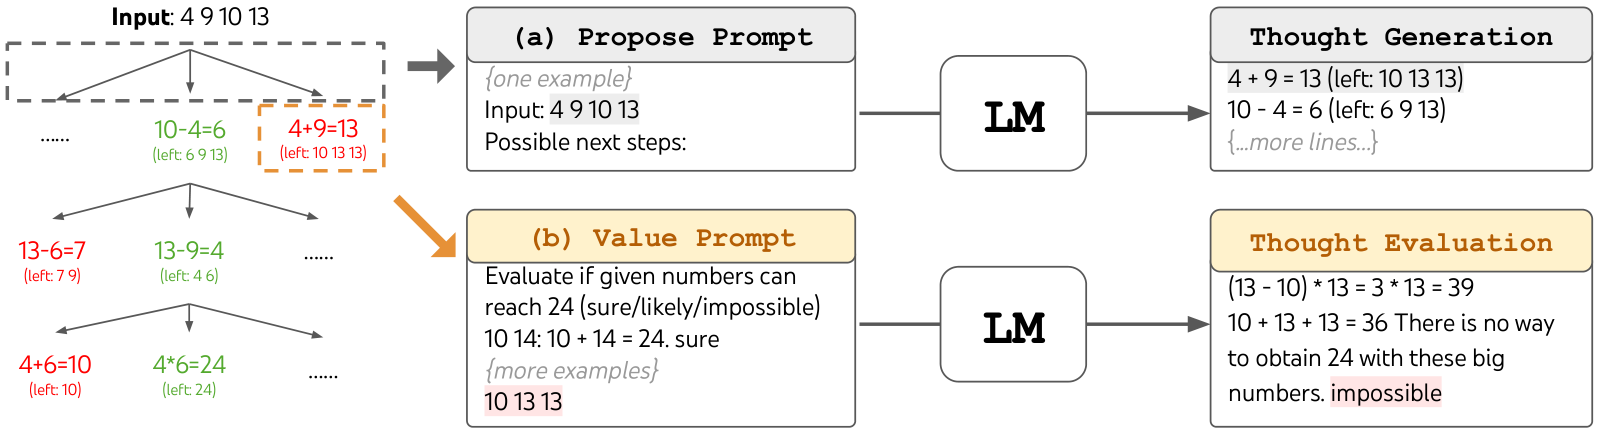

*Paper Figure 2 — "ToT in a game of 24. The LM is prompted for (a) thought generation and (b) valuation."*

Read it left to right: the search is at state `4 9 10 13`. **(a)** The *propose prompt* asks the LM to enumerate possible next steps (`4 + 9 = 13 (left: 10 13 13)`, …) — that is our `ThoughtGenerator` (Step 4). **(b)** Each resulting state is fed to the *value prompt*, which reasons briefly and ends with a verdict — `sure / likely / impossible` — that is our `StateEvaluator` (Step 5). The red branch `4 + 9 = 13 → (left: 10 13 13)` gets judged `impossible` ("there is no way to obtain 24 with these big numbers") and is pruned; green branches like `10 - 4 = 6` survive and are expanded.

## Step 4: Thought Generator G(·) — the Propose Prompt (Figure 2a)

For Game of 24 the paper uses the **propose** strategy: the thought space is constrained (one equation line), so asking for k candidates *in one prompt* avoids the duplicates that i.i.d. sampling would produce.

Two details worth noticing from the paper:
- The official propose prompt is **1-shot** — a single worked example (`Input: 2 8 8 14`) is enough to lock in the output format. We use that example verbatim below.
- **The same propose prompt is reused at all 3 thought steps**, even though it only shows a 4-number example — it generalizes to 3- and 2-number states.

**📝 EXERCISE:** Complete the `propose` method using the prompt skeleton below.

In [ ]:
# The official repo's propose prompt example, verbatim (1-shot)
PROPOSE_EXAMPLES = """
Input: 2 8 8 14
Possible next steps:
2 + 8 = 10 (left: 8 10 14)
8 / 2 = 4 (left: 4 8 14)
14 + 2 = 16 (left: 8 8 16)
2 * 8 = 16 (left: 8 14 16)
8 - 2 = 6 (left: 6 8 14)
14 - 8 = 6 (left: 2 6 8)
14 / 2 = 7 (left: 7 8 8)
14 - 2 = 12 (left: 8 8 12)
""".strip()


class ThoughtGenerator:
    """G(p_theta, s, k) — propose strategy with few-shot prompting (§3 point 2b)."""

    def __init__(self, llm: LLMClient, k: int = 5):
        self.llm = llm
        self.k = k

    def propose(self, state: str) -> List[str]:
        prompt = (f"{PROPOSE_EXAMPLES}\n\n"
                  f"Input: {state}\n"
                  f"Possible next steps:")
        response = self.llm.generate(prompt, max_tokens=300)

        steps = []
        for line in response.splitlines():
            # strip list bullets ("1. ", "2) ", "- ", "* ") but never a bare
            # leading operand like "4 " in "4 + 9 = 13"
            line = re.sub(r"^\s*(?:[-*\u2022]|\d+[.)])\s+", "", line).strip()
            if "=" in line and any(op in line for op in ["+", "-", "*", "/"]):
                steps.append(line)
        return steps[:self.k] if steps else [response]

print("✓ ThoughtGenerator defined")

## Step 5: State Evaluator V(·) — the Value Prompt (Figure 2b)

The paper's value prompt classifies each state as **`sure / likely / impossible`** with respect to reaching 24, and each state is **sampled 3× and aggregated**. The verdicts are turned into numbers using the official repo's (self-described "ad hoc") weights:

```python
value_map = {'sure': 20, 'likely': 1, 'impossible': 0.001}
```

The wide gap between `sure` and `likely` makes one confident verdict outweigh many hedges; `impossible` states effectively drop out of the top-b selection. The intent (§3 point 3a): *lookahead* promotes states that can be verified to reach 24 within a couple of trials, and *commonsense* ("too big / too small") eliminates hopeless ones.

**Our upgrade — Python-backed verification.** Because this task is mathematical, `solve24()` can settle many verdicts *exactly*, so the LLM is consulted only where its judgment adds information:

```
state == "24"              → sure        (solved — no LLM call)
solve24 says unsolvable    → impossible  (prune — no LLM call)
solve24 says solvable      → LLM judges the quality of this partial path, 3 samples
```

This makes evaluation robust to small-model errors *without* changing the search: the paper's GPT-4 evaluator was approximating exactly this decision.

**📝 EXERCISE:** Complete `value_single` and `evaluate`.

In [ ]:
# Official repo weights — note the deliberately huge gap sure >> likely
VERDICT_SCORES = {"sure": 20.0, "likely": 1.0, "impossible": 0.001}

# Condensed from the official value prompt: reason with lookahead +
# commonsense, then end with one verdict word.
VALUE_EXAMPLES = """
Evaluate if given numbers can reach 24 (sure/likely/impossible)

Remaining: 10 14
10 + 14 = 24. sure

Remaining: 4 4 10
4 + 4 + 10 = 18; 4 * 10 - 4 = 36; (10 - 4) * 4 = 24. sure

Remaining: 5 7 8
5 + 7 + 8 = 20; (8 - 5) * 7 = 21. Cannot obtain 24 now, but numbers are within a reasonable range. likely

Remaining: 10 10 11
10 + 10 + 11 = 31; (11 - 10) * 10 = 10. 10 10 11 are all too big. impossible

Remaining: 1 3 3
1 * 3 * 3 = 9; (1 + 3) * 3 = 12. 1 3 3 are all too small. impossible
""".strip()


class StateEvaluator:
    """
    V(p_theta, S) — value strategy with Python-backed verification (§3 point 3a).

    Evaluation hierarchy:
      1. State == "24"             → sure  (solved)
      2. solve24 says impossible   → impossible  (prune immediately)
      3. solve24 confirms solvable → sample LLM n_samples times for quality score
    """

    def __init__(self, llm: LLMClient, n_samples: int = 3):
        self.llm = llm
        self.n_samples = n_samples

    def _state_to_nums(self, state: str) -> List[float]:
        try:
            return [float(x) for x in state.split()]
        except ValueError:
            return []

    def value_single(self, state: str) -> str:
        prompt = (f"{VALUE_EXAMPLES}\n\n"
                  f"Remaining: {state}\n"
                  f"Evaluate briefly, then end with exactly one word — sure, likely, or impossible:")
        response = self.llm.generate(prompt, max_tokens=60)
        for line in reversed(response.splitlines()):
            word = line.strip().lower().rstrip(".")
            if word in VERDICT_SCORES:
                return word
        return "likely"

    def evaluate(self, node: ToTNode) -> float:
        # 1. Exact solution
        if node.state.strip() == "24":
            return VERDICT_SCORES["sure"]
        # 2. Parse state
        nums = self._state_to_nums(node.state)
        if not nums:
            return VERDICT_SCORES["likely"]
        # 3. Provably impossible — prune immediately, no LLM call needed
        if not solve24(nums):
            return VERDICT_SCORES["impossible"]
        # 4. Solvable — let LLM judge the quality of this partial path
        verdicts = [self.value_single(node.state) for _ in range(self.n_samples)]
        return sum(VERDICT_SCORES[v] for v in verdicts) / len(verdicts)

print("✓ StateEvaluator defined")

## Step 6: BFS Search — Algorithm 1

The paper's **ToT-BFS** keeps the *b* most promising states per step:

```
Algorithm 1  ToT-BFS(x, p_θ, G, k, V, T, b)
────────────────────────────────────────────────────────────
S₀ ← {x}
for t = 1 … T:
    S'ₜ ← {[s, z] | s ∈ Sₜ₋₁,  z ∈ G(p_θ, s, k)}     # generate
    Vₜ  ← V(p_θ, S'ₜ)                                 # evaluate
    Sₜ  ← argmax over S ⊂ S'ₜ, |S| = b of  Σ Vₜ(s)    # select top-b
return G(p_θ, argmax Vₜ(s), 1)
────────────────────────────────────────────────────────────
```

For Game of 24: **T = 3** (each step merges two numbers: 4 → 3 → 2 → 1) and **b = 5**. BFS suits problems where the tree is shallow (T ≤ 3) and early steps can be evaluated and pruned to a small set.

The paper's companion **Algorithm 2 (ToT-DFS)** — used for its Crosswords task — instead dives into the most promising child first, *prunes* any subtree whose value falls below a threshold, and *backtracks* to the parent to try siblings. Depth-first suits deep trees (a crossword needs 5–10 dependent moves) where maintaining a wide frontier would explode.

One implementation note: after `G(·)` proposes thoughts, we pass each through `parse_equation` and discard invalid ones *before* evaluation — deterministic filtering the paper left to the LLM.

In [ ]:
class ToTBFS:
    """ToT-BFS — Algorithm 1 from the paper."""

    def __init__(self, llm: LLMClient, k: int = 5, b: int = 5, T: int = 3):
        self.generator = ThoughtGenerator(llm, k)
        self.evaluator = StateEvaluator(llm)
        self.llm       = llm
        self.b         = b
        self.T         = T

    def solve(self, numbers: str, verbose: bool = False) -> SearchResult:
        t0   = time.time()
        root = ToTNode(state=numbers, thought="[START]", depth=0)
        frontier: List[ToTNode] = [root]
        explored = 0

        for step in range(1, self.T + 1):
            if verbose:
                print(f"\n── Step {step}/{self.T}  ({len(frontier)} state(s)) ──")

            # A: generate + parse (deterministic arithmetic check)
            candidates: List[ToTNode] = []
            for node in frontier:
                node_nums = [float(x) for x in node.state.split()]
                for thought in self.generator.propose(node.state):
                    valid, remaining = parse_equation(thought, node_nums)
                    if not valid:
                        continue
                    state_str = " ".join(str(int(x) if x == int(x) else x)
                                        for x in remaining)
                    child = ToTNode(state=state_str, thought=thought,
                                    depth=step, parent=node)
                    node.children.append(child)
                    candidates.append(child)

            explored += len(candidates)
            if not candidates:
                break

            # B: evaluate (Python solver + LLM for ambiguous states)
            for child in candidates:
                child.score = self.evaluator.evaluate(child)

            if verbose:
                for c in sorted(candidates, key=lambda n: n.score, reverse=True)[:5]:
                    print(f"  score={c.score:6.2f}  {c.thought[:65]}")

            # C: solution check
            for child in candidates:
                if child.state.strip() == "24":
                    path = child.path()
                    if verbose:
                        print(f"\n✅ Solution: {' → '.join(path)}")
                    return SearchResult(solution=" → ".join(path),
                                        nodes_explored=explored,
                                        elapsed=time.time() - t0, root=root)

            # D: keep top-b
            frontier = sorted(candidates, key=lambda n: n.score, reverse=True)[:self.b]

        return SearchResult(solution=None, nodes_explored=explored,
                            elapsed=time.time() - t0, root=root)

    def visualize(self, root: ToTNode, max_depth: int = 3):
        print("\n🌳 Thought Tree (ToT-BFS)\n" + "="*60)
        def show(node, prefix="", last=True):
            conn = "└── " if last else "├── "
            label = (f"{node.thought[:58]}  [score={node.score:.2f}]"
                     if node.depth else f"ROOT: {node.state}")
            print(f"{prefix}{conn if node.depth else ''}{label}")
            if node.depth < max_depth:
                ext = "    " if last else "│   "
                for i, c in enumerate(node.children):
                    show(c, prefix + ext, i == len(node.children) - 1)
        show(root)
        print("="*60)

print("✓ ToTBFS defined")

## A Note on Model Choice (Before Running)

The paper used **GPT-4**, and its Appendix B ("Extension to new LMs") shows **generation quality is the bottleneck** — same method, different base model (Table 6):

| Method | GPT-4 | GPT-3.5 |
|---|---|---|
| IO | 7.3% | 6% |
| CoT | 4.0% | 3% |
| **ToT (b=5)** | **74%** | **19%** |

`ToT > CoT > IO` holds for both models, but the *absolute* gain collapses with the weaker generator. The same effect dominates locally:

| Model | Game of 24 ToT behaviour |
|---|---|
| Qwen 0.5B | proposes ~no valid moves — the tree never grows past the root (0 nodes) |
| **Qwen 3B (default)** | proposes parseable steps; the search explores and solves some instances |
| Qwen 7B | best local fidelity; closest to the paper's regime |
| GPT-4 (paper) | 74% |

Set `MODEL_NAME` in the imports cell to switch. **3B/7B are much slower on CPU** — a GPU is used automatically when available; on CPU, reduce `T`, `k`, or the number of benchmark puzzles to keep runtimes reasonable.

**Why the model matters:** `parse_equation` and `solve24` already make *parsing and evaluation* robust to model errors — but they cannot invent good moves. Proposing valid next steps is the generator's job, and that needs a capable model.

## Demo: Game of 24

We use `4 9 10 13` — the exact instance walked through in the paper's Figure 2 (and one of the five examples in its IO prompt, where the reference answer is `(13 - 9) * (10 - 4) = 24`). Watch the verbose trace and match it against the figure: proposals appear, `impossible` states are pruned, and the frontier narrows to the top b = 5.

> ⏱️ With a 3B/7B model on CPU each propose+evaluate step is slow — a GPU is strongly recommended.

In [ ]:
numbers = "4 9 10 13"

tot    = ToTBFS(llm, k=5, b=5, T=3)
result = tot.solve(numbers, verbose=True)

print("\n" + "="*60)
if result.solution:
    print(f"✅ Solution: {result.solution}")
else:
    print("❌ No solution found within search limits")
print(f"Nodes explored: {result.nodes_explored}  |  Time: {result.elapsed:.1f}s")

### Visualize the Search Tree

The printed tree is the notebook's equivalent of Figure 2's left panel: every parsed proposal appears as a branch, scores come from `V(·)`, and pruned branches simply have no children.

In [ ]:
tot.visualize(result.root)

### Run on the Paper's Actual Test Puzzles

The paper reports success rate over games 901–1,000 of the 4nums.com scrape. Running all 100 locally would take hours, so we take the **first five games of the paper's own test slice** — note their human difficulty stats printed alongside (`AMT` = mean human solve time). Success uses the paper's criterion: the search must reach state `24` through equations that `parse_equation` verified use only the remaining numbers.

In [ ]:
N_PUZZLES    = 5
test_rows    = paper_test_df.head(N_PUZZLES)
tot_results  = {}

for _, row in test_rows.iterrows():
    puzzle = row["Puzzles"]
    r = tot.solve(puzzle, verbose=False)
    tot_results[puzzle] = r
    icon = "✅" if r.solution else "❌"
    print(f"{icon}  rank {row['Rank']:>4}  {puzzle:<12}  "
          f"human: {row['AMT (s)']:.1f}s / {row['Solved rate']} solved   "
          f"nodes={r.nodes_explored:3d}  time={r.elapsed:.1f}s")
    if r.solution:
        print(f"       {r.solution}")

solved = sum(1 for r in tot_results.values() if r.solution)
print(f"\nToT solved {solved}/{N_PUZZLES} "
      f"(paper: GPT-4 74%, GPT-3.5 19% over the full 100)")

## Benchmark: Reproducing Table 2 — IO vs. CoT vs. ToT

The paper's headline result (Table 2, Game of 24, GPT-4):

| Method | Success |
|---|---|
| IO prompt | 7.3% |
| CoT prompt | 4.0% |
| CoT-SC (k=100) | 9.0% |
| ToT (b=1) | 45% |
| **ToT (b=5)** | **74%** |
| IO + Refine (k=10) | 27% |
| IO (best of 100) | 33% |
| CoT (best of 100) | 49% |

Details worth knowing about the baselines (§4.1): IO uses **5 in-context examples**; CoT augments each with **3 intermediate equations**; both were sampled **100× per game** and averaged. CoT-SC takes the majority answer of 100 CoT samples, and IO+Refine iterates *"reflect on your mistakes and generate a refined answer"* up to 10 times using ground-truth correctness feedback. Even an **oracle** that takes the best of 100 CoT samples reaches only 49% — worse than ToT visiting far fewer states. And curiously, plain **CoT (4.0%) is *worse* than IO (7.3%)** here: a wrong first equation dooms the whole chain.

Below we run the paper's **verbatim IO and CoT prompts** (from the official repo) on the same test puzzles as above, score them with our deterministic `check_answer`, and compare against ToT. With 5 puzzles × 1 sample on a small model the numbers are noisy — what should replicate is the *ordering* and the *failure mode* (CoT committing early to a bad step).

In [ ]:
# The paper's baseline prompts, verbatim from the official repo (5-shot)
IO_PROMPT = """Use numbers and basic arithmetic operations (+ - * /) to obtain 24.
Input: 4 4 6 8
Answer: (4 + 8) * (6 - 4) = 24
Input: 2 9 10 12
Answer: 2 * 12 * (10 - 9) = 24
Input: 4 9 10 13
Answer: (13 - 9) * (10 - 4) = 24
Input: 1 4 8 8
Answer: (8 / 4 + 1) * 8 = 24
Input: 5 5 5 9
Answer: 5 + 5 + 5 + 9 = 24
Input: {input}
"""

COT_PROMPT = """Use numbers and basic arithmetic operations (+ - * /) to obtain 24. Each step, you are only allowed to choose two of the remaining numbers to obtain a new number.
Input: 4 4 6 8
Steps:
4 + 8 = 12 (left: 4 6 12)
6 - 4 = 2 (left: 2 12)
2 * 12 = 24 (left: 24)
Answer: (6 - 4) * (4 + 8) = 24
Input: 2 9 10 12
Steps:
12 * 2 = 24 (left: 9 10 24)
10 - 9 = 1 (left: 1 24)
24 * 1 = 24 (left: 24)
Answer: (12 * 2) * (10 - 9) = 24
Input: 4 9 10 13
Steps:
13 - 10 = 3 (left: 3 4 9)
9 - 3 = 6 (left: 4 6)
4 * 6 = 24 (left: 24)
Answer: 4 * (9 - (13 - 10)) = 24
Input: 1 4 8 8
Steps:
8 / 4 = 2 (left: 1 2 8)
1 + 2 = 3 (left: 3 8)
3 * 8 = 24 (left: 24)
Answer: (1 + 8 / 4) * 8 = 24
Input: 5 5 5 9
Steps:
5 + 5 = 10 (left: 5 9 10)
10 + 5 = 15 (left: 9 15)
15 + 9 = 24 (left: 24)
Answer: ((5 + 5) + 5) + 9 = 24
Input: {input}
"""


def extract_answer(response: str) -> str:
    """Pull the expression out of the last 'Answer: ...' line."""
    answers = re.findall(r"Answer:\s*(.+)", response)
    return answers[-1].strip() if answers else response.strip()


def run_baseline(prompt_template: str, puzzle: str, max_tokens: int = 300):
    t0 = time.time()
    response = llm.generate(prompt_template.format(input=puzzle), max_tokens=max_tokens)
    answer = extract_answer(response)
    return {"answer": answer,
            "correct": check_answer(puzzle, answer),
            "elapsed": time.time() - t0}

print("✓ IO and CoT baselines ready (official prompts)")

In [ ]:
assert tot_results, "Run the ToT benchmark cell above first — tot_results is empty."

rows = []
for _, row in tqdm(list(test_rows.iterrows()), desc="Benchmarking"):
    puzzle = row["Puzzles"]

    io_r  = run_baseline(IO_PROMPT, puzzle, max_tokens=60)
    cot_r = run_baseline(COT_PROMPT, puzzle, max_tokens=300)
    tot_r = tot_results[puzzle]          # reuse the ToT runs from above
    tot_ok = tot_r.solution is not None

    rows += [
        {"method": "IO",  "puzzle": puzzle, "correct": io_r["correct"],  "time": io_r["elapsed"]},
        {"method": "CoT", "puzzle": puzzle, "correct": cot_r["correct"], "time": cot_r["elapsed"]},
        {"method": "ToT", "puzzle": puzzle, "correct": tot_ok,           "time": tot_r.elapsed},
    ]

bench_df = pd.DataFrame(rows)
summary = (bench_df.groupby("method")["correct"]
           .agg(success_rate="mean", solved="sum", total="count")
           .reindex(["IO", "CoT", "ToT"]))
print(summary.round(3))
print("\nAvg seconds per puzzle:")
print(bench_df.groupby("method")["time"].mean().reindex(["IO", "CoT", "ToT"]).round(1))

In [ ]:
PAPER_GPT4 = {"IO": 0.073, "CoT": 0.040, "ToT": 0.74}

methods = ["IO", "CoT", "ToT"]
local   = [summary.loc[m, "success_rate"] for m in methods]
paper   = [PAPER_GPT4[m] for m in methods]

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

x, w = np.arange(len(methods)), 0.35
axes[0].bar(x - w/2, local, w, label=f"local ({MODEL_NAME.split('/')[-1]})", color="steelblue")
axes[0].bar(x + w/2, paper, w, label="paper (GPT-4, 100 games)", color="coral")
axes[0].set(title="Game of 24 success rate", ylabel="Success rate",
            xticks=x, xticklabels=methods, ylim=[0, 1])
axes[0].legend()

bench_df.groupby("method")["time"].mean().reindex(methods).plot(
    kind="bar", ax=axes[1], color="steelblue")
axes[1].set(title="Avg time per puzzle (s)", ylabel="Seconds")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

> ⏱️ ToT makes **many LLM calls per puzzle** (k proposals × b states × T steps, plus 3 value samples per surviving state) versus one call for IO/CoT — that is the deliberate compute-for-accuracy trade the paper makes, and why the timing panel above is as much a result as the accuracy panel. On CPU, reduce `N_PUZZLES` or `k`/`b` for a quicker run.

## Reflection

1. **Four design questions** (§3): For Game of 24 the paper chose *propose + value + BFS*. What would change if you used *sample* instead of *propose*? Or *vote* instead of *value*?

2. **Python verifier**: `solve24()` gives exact verdicts where the paper's LLM could only approximate, and `check_answer()` replaces the paper's LLM judge (`value_last_step_prompt`). What kinds of problems (the paper's Creative Writing task, say) *can't* be verified with deterministic code — and what does V(·) have to do instead?

3. **The scraped benchmark**: The paper chose games 901–1,000 *because* the 4nums.com difficulty ranking (human solve time) let it select hard instances. Using the `AMT (s)` column, how would you test whether ToT's advantage over CoT *grows* with difficulty? What are the risks of benchmarking on data scraped from a public puzzle site (contamination, licensing, ranking bias)?

4. **First-step failures**: The paper's error analysis found ~60% of CoT samples fail at the first of three steps. Look at your CoT baseline outputs — does the same pattern appear? Why does ToT's breadth (b = 5) specifically address this failure mode?

5. **BFS vs DFS** (Algorithms 1 & 2): The paper uses BFS for Game of 24 and DFS for crosswords. What property of each problem drives that choice?

6. **Small vs large models**: Appendix B shows ToT drops from 74% (GPT-4) to 19% (GPT-3.5), and locally a 0.5B model can't grow the tree at all. Given that ToT costs many times more calls than CoT, when is it worth the compute?

## Summary

### Paper → Notebook mapping

| Paper concept | Notebook implementation |
|---|---|
| Game of 24 data scraped from 4nums.com (§4.1) | `game24_df` — the official repo's `24.csv`, test slice rows 901–1,000 |
| Success criterion ("valid equation, equals 24, each input once") | `check_answer()` — deterministic version of the paper's LLM judge |
| Thought generator G(·), propose strategy (Fig. 2a) | `ThoughtGenerator.propose()` with the official 1-shot propose prompt |
| State evaluator V(·), value strategy (Fig. 2b) | `StateEvaluator` — `sure / likely / impossible` sampled 3×, official weights 20 / 1 / 0.001 |
| Python-backed pruning (our upgrade) | `solve24()` exact verdicts; `parse_equation()` verifies each step |
| ToT-BFS, Algorithm 1 (b=5, T=3) | `ToTBFS.solve()` |
| IO / CoT baselines (§4.1) | `run_baseline()` with the official 5-shot prompts |
| State s = [x, z₁…ᵢ]; thought z = one equation | `ToTNode.state` / `ToTNode.thought` |

### Key results from the paper (Game of 24)

| Method | GPT-4 | GPT-3.5 |
|---|---|---|
| IO prompt | 7.3% | 6% |
| CoT prompt | 4.0% | 3% |
| CoT-SC (k=100) | 9.0% | — |
| ToT (b=1) | 45% | — |
| **ToT (b=5)** | **74%** | **19%** |
| CoT (oracle best-of-100) | 49% | — |

Plus the error analysis: ~60% of CoT samples fail at the very first equation — the single number that best explains why searching over thoughts beats sampling one chain.

### Resources
- [Paper (arXiv 2305.10601)](https://arxiv.org/abs/2305.10601) — NeurIPS 2023
- [Official code, prompts & the 4nums.com scrape](https://github.com/princeton-nlp/tree-of-thought-llm)
- [4nums.com difficulty ranking](https://www.4nums.com/game/difficulties/) — source of the benchmark
- [Hugging Face Transformers](https://huggingface.co/docs/transformers/)